# Fluorescencia vs longitud de onda

Columnas de los archivos (la frecuencia es exactamente $\nu = c/\lambda$):

| Carpeta | col 0 | col 1 | col 2 | col 3 | col 4 | col 5 |
|---|---|---|---|---|---|---|
| `data/` | — | $\lambda$ (nm) | Singles A (cuentas/s) | $\nu$ (THz) | — | — |
| `newdata/` | — | $\lambda$ (nm) | Singles A (cuentas/s) | Singles B (cuentas/s) | $\nu$ (THz) | |

El láser se barre con una onda triangular; cada rampa monótona de $\lambda$ es un *ciclo*.
Se promedian los últimos 3 ciclos agrupando los puntos en bins de frecuencia (media ± desviación estándar)
y se ajusta: 3 Lorentzianas con línea base común para los valles de 794 nm, y una Gaussiana para el pico de 822 nm.

In [1]:
import os, glob
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.ndimage import uniform_filter1d

C_LIGHT = 299792.458  # nm*THz

# Carpeta 2Lasers (en Colab: clonar el repo y hacer %cd Proyecto/2Lasers)
BASE = '.'

ModuleNotFoundError: No module named 'numpy'

In [3]:
def load(path):
    d = np.loadtxt(path)
    if d.shape[1] == 6:  # data/
        return dict(lam=d[:, 1], A=d[:, 2], B=None, nu=d[:, 3])
    return dict(lam=d[:, 1], A=d[:, 2], B=d[:, 3], nu=d[:, 4])  # newdata/

def ramps(lam, w=9, dist=40):
    # Índices de cada rampa del barrido triangular, cortando en los extremos de lambda
    s = uniform_filter1d(lam, w)
    t = np.sort(np.r_[find_peaks(s, distance=dist)[0], find_peaks(-s, distance=dist)[0]])
    edges = np.r_[0, t, len(lam)]
    return [np.arange(a, b) for a, b in zip(edges[:-1], edges[1:]) if b - a > 5]

def average_last(x, y, segs, n=3, bin_w=5.0):
    # Promedia los últimos n ciclos en bins de ancho bin_w (mismas unidades que x)
    idx = np.concatenate(segs[-n:])
    idx = idx[y[idx] > 0]
    xb = np.floor(x[idx] / bin_w) * bin_w + bin_w / 2
    ux = np.unique(xb)
    m = np.array([y[idx][xb == u].mean() for u in ux])
    s = np.array([y[idx][xb == u].std() for u in ux])
    return ux, m, s

def lorentz(x, x0, g, a):
    return a * (g / 2)**2 / ((x - x0)**2 + (g / 2)**2)

def dips(x, c, *p):
    return c + 0 * x - sum(lorentz(x, *p[i:i + 3]) for i in range(0, len(p), 3))

def gauss(x, c, x0, s, a):
    return c + a * np.exp(-(x - x0)**2 / (2 * s**2))

def fit_dips(x, y, n=3):
    c0 = np.percentile(y, 90)
    ys = uniform_filter1d(y, 5)
    pk, pr = find_peaks(c0 - ys, distance=max(3, len(x) // 20), prominence=0.05 * c0)
    pk = np.sort(pk[np.argsort(pr['prominences'])[::-1][:n]])
    p0 = [c0]
    for k in pk:
        p0 += [x[k], 40.0, c0 - ys[k]]
    popt, pcov = curve_fit(dips, x, y, p0=p0, maxfev=20000)
    return popt, np.sqrt(np.diag(pcov))

def fit_peak(x, y):
    k = np.argmax(uniform_filter1d(y, 5))
    p0 = [np.percentile(y, 5), x[k], (x.max() - x.min()) / 10, y[k]]
    popt, pcov = curve_fit(gauss, x, y, p0=p0, maxfev=20000)
    return popt, np.sqrt(np.diag(pcov))

def scan(path, ch='A', n=3, bin_mhz=5.0):
    # Devuelve detuning (MHz), lambda (nm), media, std y la frecuencia de referencia (THz)
    D = load(path)
    ref = np.floor(D['nu'].min() * 100) / 100
    det = (D['nu'] - ref) * 1e6
    x, m, s = average_last(det, D[ch], ramps(D['lam']), n=n, bin_w=bin_mhz)
    return x, C_LIGHT / (ref + x * 1e-6), m, s, ref

## Reproducción de la figura original (eje en MHz)

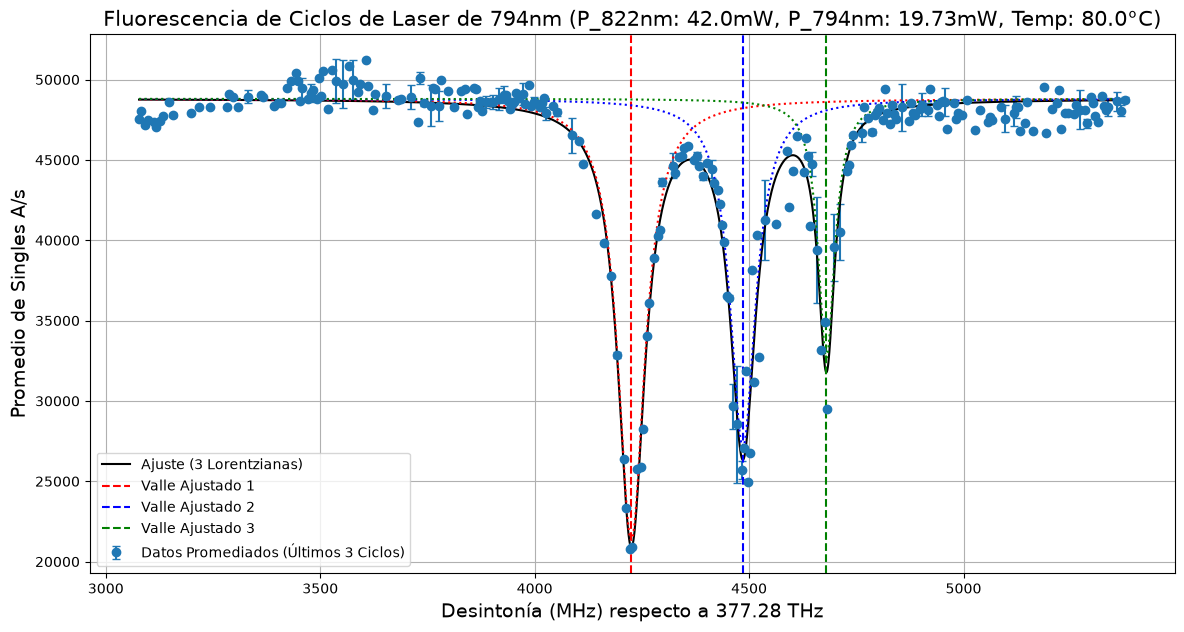

Línea base: 48802 ± 105 cuentas/s
Valle 1: 4225.4 ± 1.0 MHz  (λ = 794.606394 nm), FWHM = 76.5 ± 3.2 MHz, profundidad = 27457 ± 671
Valle 2: 4485.5 ± 1.1 MHz  (λ = 794.605846 nm), FWHM = 72.0 ± 3.4 MHz, profundidad = 21659 ± 627
Valle 3: 4680.4 ± 1.5 MHz  (λ = 794.605436 nm), FWHM = 47.2 ± 3.7 MHz, profundidad = 16116 ± 862


In [4]:
f = os.path.join(BASE, 'data', '42-19.73-30-6-150-80.txt')
x, lam, m, s, ref = scan(f)
popt, perr = fit_dips(x, m)

plt.figure(figsize=(14, 7))
plt.errorbar(x, m, yerr=s, fmt='o', capsize=3, label='Datos Promediados (Últimos 3 Ciclos)')
xx = np.linspace(x.min(), x.max(), 2000)
plt.plot(xx, dips(xx, *popt), 'k-', lw=1.5, label='Ajuste (3 Lorentzianas)')
for j, col in zip(range(3), ['red', 'blue', 'green']):
    x0, g, a = popt[1 + 3*j: 4 + 3*j]
    plt.plot(xx, popt[0] - lorentz(xx, x0, g, a), ':', color=col)
    plt.axvline(x0, ls='--', color=col, label=f'Valle Ajustado {j+1}')
plt.title('Fluorescencia de Ciclos de Laser de 794nm (P_822nm: 42.0mW, P_794nm: 19.73mW, Temp: 80.0°C)', fontsize=15)
plt.xlabel(f'Desintonía (MHz) respecto a {ref} THz', fontsize=14)
plt.ylabel('Promedio de Singles A/s', fontsize=14)
plt.grid(True)
plt.legend()
plt.show()

print(f'Línea base: {popt[0]:.0f} ± {perr[0]:.0f} cuentas/s')
for j in range(3):
    x0, g, a = popt[1 + 3*j: 4 + 3*j]
    ex0, eg, ea = perr[1 + 3*j: 4 + 3*j]
    print(f'Valle {j+1}: {x0:.1f} ± {ex0:.1f} MHz  (λ = {C_LIGHT/(ref + x0*1e-6):.6f} nm), '
          f'FWHM = {abs(g):.1f} ± {eg:.1f} MHz, profundidad = {a:.0f} ± {ea:.0f}')

## Cuentas vs longitud de onda — todos los barridos

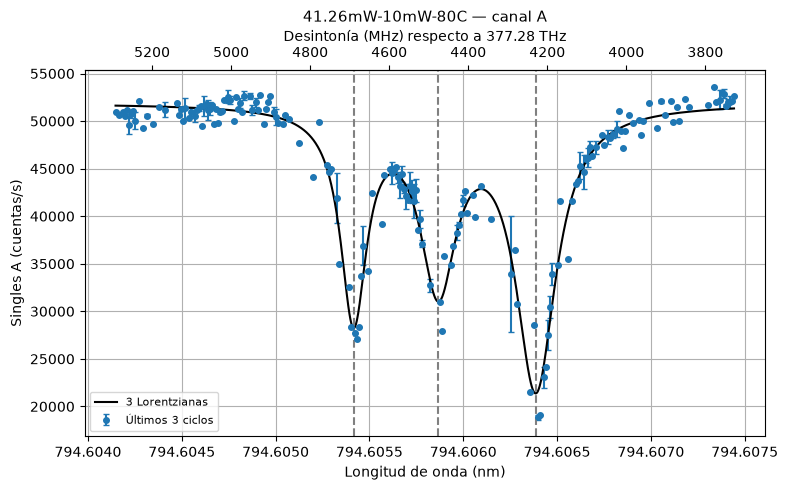

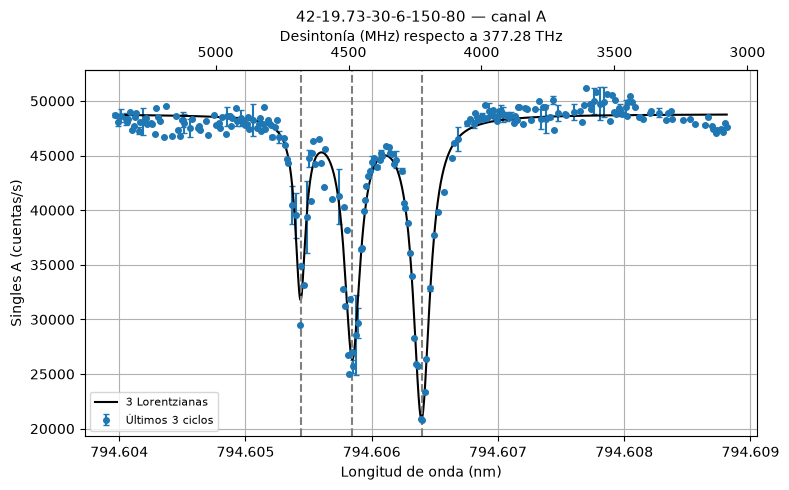

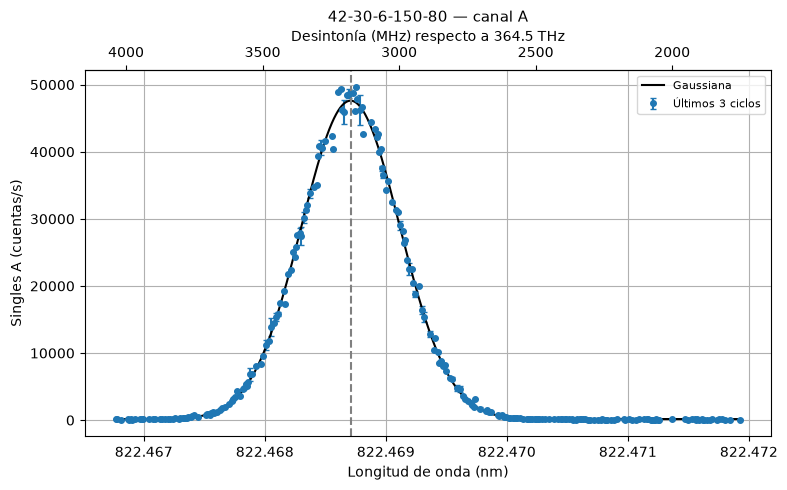

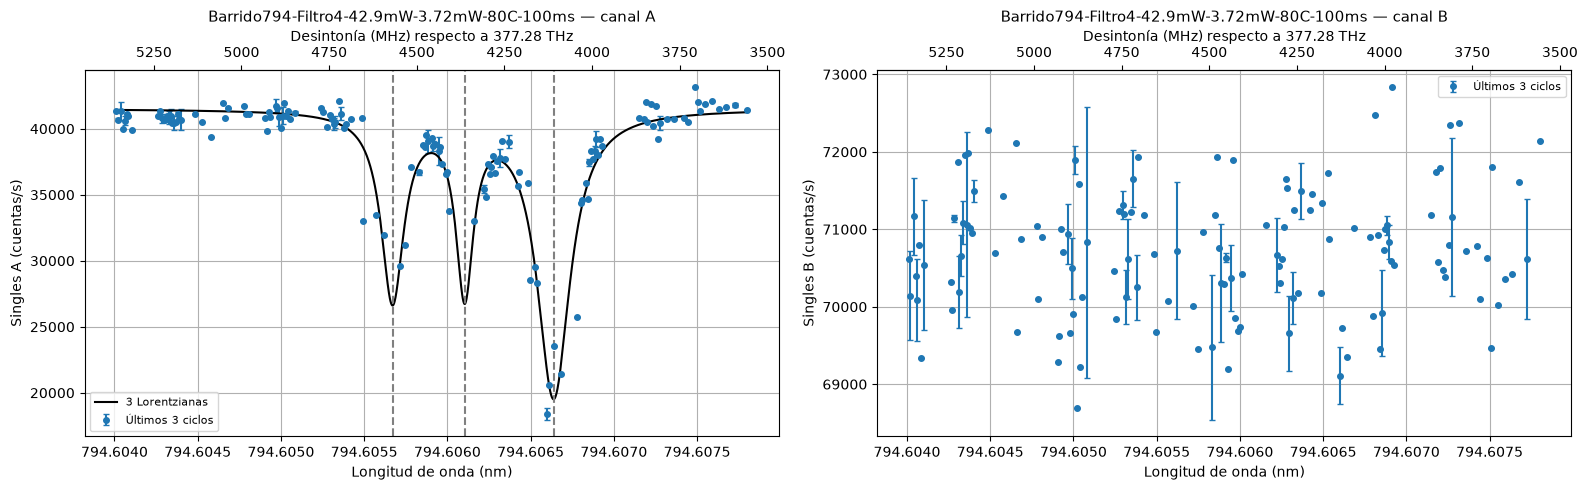

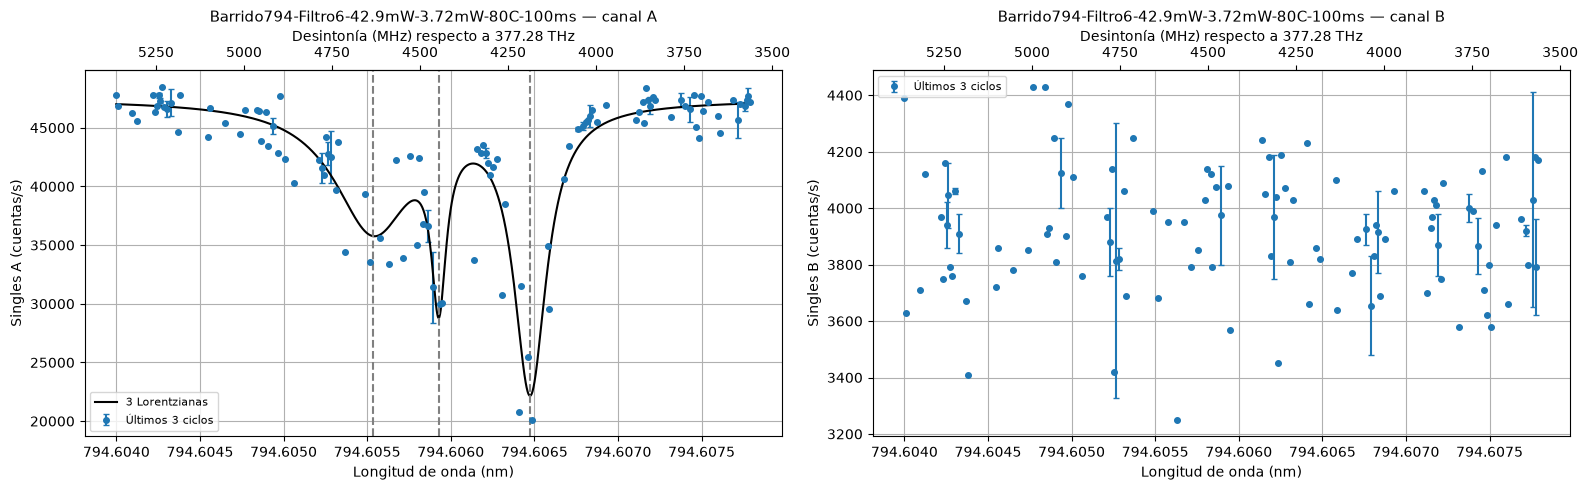

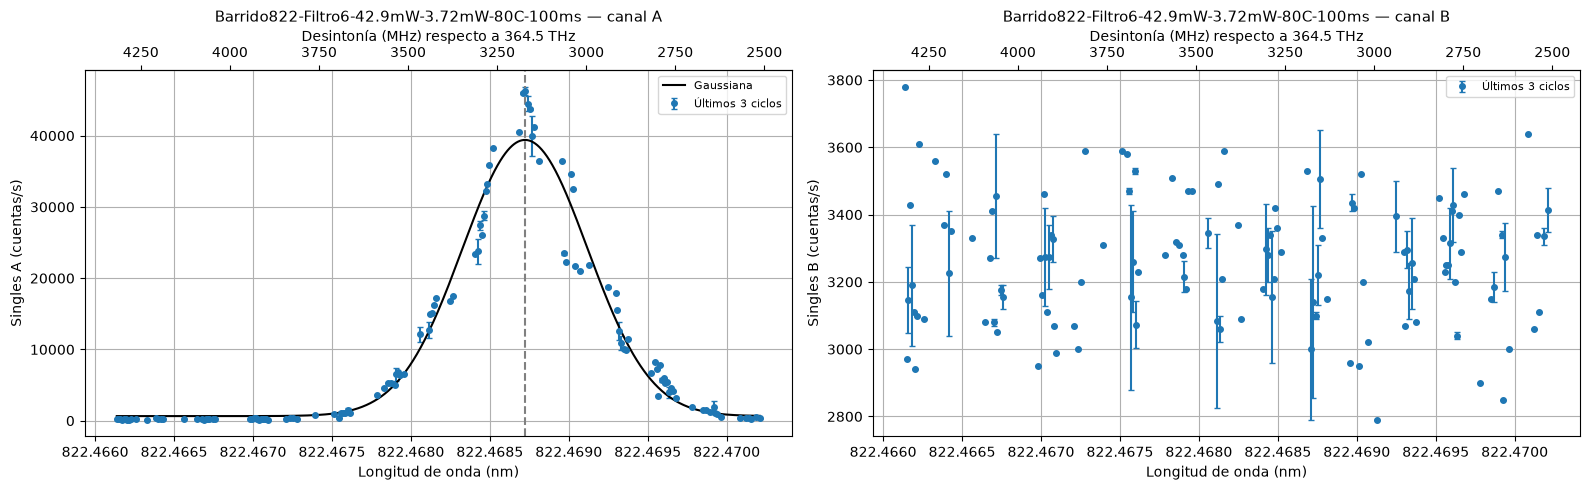

archivo                                                 λ0 (nm)  desint. (MHz)  FWHM (MHz)     base
41.26mW-10mW-80C                                     794.606387         4228.9       123.6    51909
41.26mW-10mW-80C                                     794.605867         4476.0       111.1    51909
41.26mW-10mW-80C                                     794.605415         4690.2        80.7    51909
42-19.73-30-6-150-80                                 794.606394         4225.4        76.5    48802
42-19.73-30-6-150-80                                 794.605846         4485.5        72.0    48802
42-19.73-30-6-150-80                                 794.605436         4680.4        47.2    48802
42-30-6-150-80                                       822.468709         3177.6       423.5      160
Barrido794-Filtro4-42.9mW-3.72mW-80C-100ms           794.606638         4109.6       113.4    41518
Barrido794-Filtro4-42.9mW-3.72mW-80C-100ms           794.606104         4363.5        60.3    41518


In [5]:
files = sorted(glob.glob(os.path.join(BASE, 'data', '*.txt')) + glob.glob(os.path.join(BASE, 'data', '*', '*.txt'))
               + glob.glob(os.path.join(BASE, 'newdata', 'Barrido*.txt')))
files = [f for f in files if 'readme' not in f]

resultados = []
for f in files:
    name = os.path.basename(f)[:-4]
    chans = ['A'] if load(f)['B'] is None else ['A', 'B']
    fig, axs = plt.subplots(1, len(chans), figsize=(8 * len(chans), 5), squeeze=False)
    for ax, ch in zip(axs[0], chans):
        x, lam, m, s, ref = scan(f, ch)
        ax.errorbar(lam, m, yerr=s, fmt='o', ms=4, capsize=2, label='Últimos 3 ciclos')
        is794 = lam.mean() < 800
        # El canal B no muestra estructura espectral: solo se ajusta el canal A
        if ch == 'A':
            xx = np.linspace(x.min(), x.max(), 2000)
            ll = C_LIGHT / (ref + xx * 1e-6)
            if is794:
                popt, perr = fit_dips(x, m)
                ax.plot(ll, dips(xx, *popt), 'k-', label='3 Lorentzianas')
                for j in range(1, len(popt), 3):
                    l0 = C_LIGHT / (ref + popt[j] * 1e-6)
                    ax.axvline(l0, ls='--', color='gray')
                    resultados.append((name, l0, popt[j], abs(popt[j + 1]), popt[0]))
            else:
                popt, perr = fit_peak(x, m)
                ax.plot(ll, gauss(xx, *popt), 'k-', label='Gaussiana')
                l0 = C_LIGHT / (ref + popt[1] * 1e-6)
                ax.axvline(l0, ls='--', color='gray')
                resultados.append((name, l0, popt[1], 2.3548 * abs(popt[2]), popt[0]))
        ax.ticklabel_format(axis='x', useOffset=False)
        ax.set_xlabel('Longitud de onda (nm)')
        ax.set_ylabel(f'Singles {ch} (cuentas/s)')
        sec = ax.secondary_xaxis('top', functions=(lambda l, r=ref: (C_LIGHT / l - r) * 1e6,
                                                   lambda d, r=ref: C_LIGHT / (r + d * 1e-6)))
        sec.set_xlabel(f'Desintonía (MHz) respecto a {ref} THz')
        ax.set_title(f'{name} — canal {ch}', fontsize=11)
        ax.grid(True)
        ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

print(f"{'archivo':50s} {'λ0 (nm)':>12s} {'desint. (MHz)':>14s} {'FWHM (MHz)':>11s} {'base':>8s}")
for r in resultados:
    print(f'{r[0]:50s} {r[1]:12.6f} {r[2]:14.1f} {r[3]:11.1f} {r[4]:8.0f}')